# Material de aula - FACENS - Redes Neurais e Deep Learning

In [ ]:
#Neste versão o bias não é incluido dentro do vetor de pesos e os calculos são separados


## <center> Perceptron Multicamadas e Classificação de Padrões - LABORATÓRIO 03 </center>

### A padronização para a saída, representando o conservante a ser aplicado, ficou definida da seguinte forma:

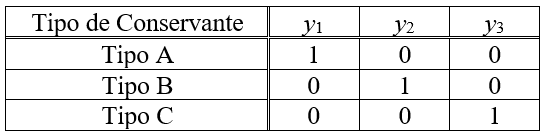

In [1]:
#CÉLULA MLP-LIB-01
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
%matplotlib inline

In [2]:
#CÉLULA MLP-LIB-02
def loadDataFile(filename) :
    '''
    Esta função faz o carregamento de dados de um arquivo separado por virgulas (csv)
    
    Parametros
    -----------
    filename -> nome do arquivo de dados em formato csv
    
    
    Retorno
    -----------  
    dataframe contendo os dados do arquivo formatados numericamente.
    '''
    
    dfFile = pd.read_csv(filename, sep=';', decimal=',', thousands='.')
    return dfFile

In [3]:
#CÉLULA MLP-LIB-03
def sigmoid(z) :
    '''
    Esta função faz o cálculo da função de ativação do tipo sigmoide
    
    Parametros
    -----------
    z -> valor do parametro a ser calculado em f(z)
    
    Retorno
    -----------  
    valor da função sigmoide correspondente ao parametro z
    '''    
    return 1/(1+np.exp(-z))

In [4]:
#CÉLULA MLP-LIB-04
def tanh_function(z) :
    '''
    Esta função faz o cálculo da função de ativação do tipo tangente hiperbolica
    
    Parametros
    -----------
    z -> valor do parametro a ser calculado em f(z)
    
    Retorno
    -----------  
    valor da função tangente hiperbolica correspondente ao parametro z
    '''        
    return np.tanh(z)

# 1 - Implementação do algoritmo de treinamento do MLP

Utilizando Jupyter e NumPy: para o problema apresentado, complete o código para construir as funções de treinamento do MLP.

## 1.1 - Ajuste o código que realiza o forward step do MLP

In [15]:
#CÉLULA MLP-LIB-05
def forward_step(vInputs, vWeights, vBias) : 
    '''
    Processa o forward step
    
    Parametros
    -----------
    vInputs  -> vetor/matriz com as entradas
    vWeights -> vetor/matriz com os vetores de pesos (é um vetor de matrizes)
    vBias    -> vetor/matriz com os vetores de bias  (é um vetor de matrizes)
    
    Retorno
    -------
    Este método retorna uma tupla contendo a saída das camadas do MLP
    (Y_1, Y_2)
    '''
    
    W_1 = vWeights[0]
    W_2 = vWeights[1]
    
    B_1 = vBias[0]
    B_2 = vBias[1]

    #FORWARD STEP
    #Calcula saída do MLP para todas as amostras, de uma vez.
    Y_0 = vInputs #so para ficar uniforme a nomenclatura dos termos
    I_1 = W_1 @ Y_0 + B_1
    Y_1 = sigmoid(I_1) #Função sigmoide na camada oculta, g1

    #IMPLEMENTE O CÓDIGO AQUI - INICIO
    ## COMPLETE O PASSO DE CALCULO DA SAIDA (UTILIZANDO FUNÇÃO SIGMOIDE, POIS AGORA SERÁ APLICADA A CLASSIFICAÇÃO DE PADRÕES)
    
    I_2 = W_2 @ Y_1 + B_2
    Y_2 = sigmoid(I_2)
    
    #IMPLEMENTE O CÓDIGO AQUI - FIM
    #FIM DO FORWARD STEP
    
    return (Y_1, Y_2)

In [16]:
#CÉLULA MLP-LIB-06
def calcMSE(vInputs, vOutputs, vWeights, vBias) : 
    '''
    Calcula o Erro Quadratico Medio (Mean Squared Error) do MLP
    
    Parametros
    -----------
    vInputs  -> vetor/matriz com as entradas
    vOutputs -> vetor/matriz com os vetores dos dados
    vWeights -> vetor/matriz com os vetores de pesos (é um vetor de matrizes)
    vBias    -> vetor/matriz com os vetores de bias  (é um vetor de matrizes)
    
    Retorno
    -------
    Este método retorna o valor de MSE para o conjunto de dados e pesos do MLP
    '''
    
    (_, Y_2) = forward_step(vInputs, vWeights, vBias)
    nSamples = vInputs.shape[1]
       
    E_k = 1/2 * (vOutputs - Y_2)**2
    E_k = np.sum(E_k, axis=1)#como tem 3 neurõnios na saída, foi colocado esta linha
    MSE = np.sum(E_k) / nSamples
    
    return np.asscalar(MSE)

## 1.2 - Ajuste o código que realiza o treinamento em BATCH

In [17]:
#CÉLULA MLP-LIB-07
def mlp_train_batch(eta, epsilon, vInputs, vOutputs, dictLayers, max_epochs) :
    '''
    Algoritmo de treinamento do Perceptron Simples
    
    Parametros
    -----------
    eta         -> taxa de aprendizado
    epsilon     -> margem de erro
    vInputs     -> vetor/matriz com as entradas
    vOutputs    -> vetor/matriz com as saidas
    dictLayers  -> dicionario que descreve as camadas da rede {'nLayers' : 'xxx', vLayers : vvv}, onde nLayers representa 
                   o numero de camadas e vLayers é um vetor linha contedo o tamanho de cada camada
    max_epochs -> criterio de parada por epocas de treinamento
    
    Retorno
    -------
    Este método retorna uma tupla contendo o vetor de pesos ajustado e o numero de epocas executadas no treinamento.
    '''
    
    #Determine numero de entradas do MLP e o numero de amostras
    nInputs  = vInputs.shape[0]
    nSamples = vInputs.shape[1]
    
    indexLayer = 1
    nNeurons      = dictLayers['vLayers'][indexLayer]   #Numero de neurons da camada 'indexLayer'
    nConnections  = dictLayers['vLayers'][indexLayer-1] #Numero de neurons da camada 'indexLayer-1'
    
    # Wji = j-esimo neuron de uma cada ao i-esimo sinal da camada de entrada (na primeira matriz de pesos)
    #assim, todos os sinais de entrada de um neuronio ficam na linha e cada linha contem 1 neuronio
    W_1 = np.random.rand(nNeurons, nConnections);
    B_1 = np.random.rand(nNeurons, 1);

    indexLayer    = 2
    nNeurons      = dictLayers['vLayers'][indexLayer]   #Numero de neurons da camada 'indexLayer'
    nConnections  = dictLayers['vLayers'][indexLayer-1] #Numero de neurons da camada 'indexLayer-1'

    # Wji = j-esimo neuron de uma cada ao i-esimo sinal da camada de entrada (na primeira matriz de pesos)
    #assim, todos os sinais de entrada de um neuronio ficam na linha e cada linha contem 1 neuronio
    W_2 = np.random.rand(nNeurons, nConnections);
    B_2 = np.random.rand(nNeurons, 1);#aqui precisa ser ajustado o BIAS da saída
    
    #Monte o loop de cálculo do erro e ajuste dos pesos
    bError = True
    MSE = [] # MSE: Mean Squared Error
    
    for epochCounter in range(max_epochs) :
        Y_0 = vInputs #esta atribuição é apenas para manter uniformidade de nomenclatura
        (Y_1, Y_2) = forward_step(vInputs, [W_1, W_2], [B_1, B_2])       

        #INICIO - BACKWARD STEP
        #IMPLEMENTE O CÓDIGO AQUI - INICIO
        ###DEFINA A DERIVADA E O GRADIENTE LOCAL DA CAMADA DE SAIDA
        
        #A derivada de g2 é igual a Y_2 * (1 - Y_2)
        diff_g2 = Y_2 * (1 - Y_2)
        #gradiente local
        delta_2 =  (vOutputs - Y_2) * diff_g2
        
        #IMPLEMENTE O CÓDIGO AQUI - FIM
        
        #Ajuste dos pesos
        #IMPLEMENTE O CÓDIGO AQUI - INICIO
        #AJUSTE OS VALORES DE W_2 E B_2
        W_2 += eta * delta_2 @ Y_1.T
        B_2 += eta * np.sum(delta_2, axis=1, keepdims=True)
        #IMPLEMENTE O CÓDIGO AQUI - FIM
        
        #Ajuste de pesos Camada Entrada - Camada Oculta
        #A derivada de g1(I_1) é igual a g1(I_1)*(1 - g1(I_1)) ou seja, Y_1*(1 - Y_1)
        diff_g1 = Y_1 * (1 - Y_1)

        #Gradiente local
        delta_1 = (W_2.T @ delta_2) * diff_g1
        
        #Ajuste dos pesos
        W_1 += eta * delta_1 @ Y_0.T
        B_1 += eta * np.sum(delta_1, axis=1, keepdims=True) #Soma das colunas de delta_1. Podemos multiplicar por um vetor coluna de [1] também                
        #FIM - BACKWARD STEP

        #Calcula o Erro Quadratico Medio
        MSE_temp = calcMSE(vInputs, vOutputs, [W_1, W_2], [B_1, B_2])
        MSE.append( MSE_temp )
        
        print( 'Epoch = {} - MSE = {}'.format(epochCounter, MSE_temp))
        
        if( epochCounter > 0 and abs(MSE[epochCounter] - MSE[epochCounter-1]) < epsilon ) :
            break
    
    return (W_1, W_2, B_1, B_2, MSE)

## 1.3 - Ajuste o código que realiza o treinamento ONLINE

In [30]:
#CÉLULA MLP-LIB-08
def mlp_train_online(eta, epsilon, vInputs, vOutputs, dictLayers, max_epochs) :
    '''
    Algoritmo de treinamento do Perceptron Simples
    
    Parametros
    -----------
    eta         -> taxa de aprendizado
    epsilon     -> margem de erro
    vInputs     -> vetor/matriz com as entradas
    vOutputs    -> vetor/matriz com as saidas
    dictLayers  -> dicionario que descreve as camadas da rede {'nLayers' : 'xxx', vLayers : vvv}, onde nLayers representa 
                   o numero de camadas e vLayers é um vetor linha contedo o tamanho de cada camada
    max_epochs -> criterio de parada por epocas de treinamento
    
    Retorno
    -------
    Este método retorna uma tupla contendo o vetor de pesos ajustado e o numero de epocas executadas no treinamento.
    '''
     #Determine numero de entradas do MLP e o numero de amostras
    nInputs  = vInputs.shape[0]
    nSamples = vInputs.shape[1]
    
    indexLayer = 1
    nNeurons      = dictLayers['vLayers'][indexLayer]   #Numero de neurons da camada 'indexLayer'
    nConnections  = dictLayers['vLayers'][indexLayer-1] #Numero de neurons da camada 'indexLayer-1'
    
    # Wji = j-esimo neuron de uma cada ao i-esimo sinal da camada de entrada (na primeira matriz de pesos)
    #assim, todos os sinais de entrada de um neuronio ficam na linha e cada linha contem 1 neuronio
    W_1 = np.random.rand(nNeurons, nConnections);
    B_1 = np.random.rand(nNeurons, 1);

    indexLayer    = 2
    nNeurons      = dictLayers['vLayers'][indexLayer]   #Numero de neurons da camada 'indexLayer'
    nConnections  = dictLayers['vLayers'][indexLayer-1] #Numero de neurons da camada 'indexLayer-1'

    # Wji = j-esimo neuron de uma cada ao i-esimo sinal da camada de entrada (na primeira matriz de pesos)
    #assim, todos os sinais de entrada de um neuronio ficam na linha e cada linha contem 1 neuronio
    W_2 = np.random.rand(nNeurons, nConnections);
    B_2 = np.random.rand(nNeurons, 1);#aqui precisa ser ajustado o BIAS da saída
    
    #Monte o loop de cálculo do erro e ajuste dos pesos
    bError = True
    MSE = [] # MSE: Mean Squared Error
    
    for epochCounter in range(max_epochs) :
        for k in range(nSamples):
            
            Y_0 = vInputs[:,[k]] #esta atribuição é apenas para manter uniformidade de nomenclatura
            (Y_1, Y_2) = forward_step(Y_0, [W_1, W_2], [B_1, B_2])       

            #INICIO - BACKWARD STEP
            #IMPLEMENTE O CÓDIGO AQUI - INICIO
            ###DEFINA A DERIVADA E O GRADIENTE LOCAL DA CAMADA DE SAIDA

            #A derivada de g2 é igual a Y_2 * (1 - Y_2)
            diff_g2 = Y_2 * (1 - Y_2)
            #gradiente local
            Y_d = vOutputs[:,[k]]
            delta_2 =  (Y_d - Y_2) * diff_g2

            #IMPLEMENTE O CÓDIGO AQUI - FIM

            #Ajuste dos pesos
            #IMPLEMENTE O CÓDIGO AQUI - INICIO
            #AJUSTE OS VALORES DE W_2 E B_2
            W_2 += eta * delta_2 @ Y_1.T
            B_2 += eta * np.sum(delta_2, axis=1, keepdims=True)
            #IMPLEMENTE O CÓDIGO AQUI - FIM

            #Ajuste de pesos Camada Entrada - Camada Oculta
            #A derivada de g1(I_1) é igual a g1(I_1)*(1 - g1(I_1)) ou seja, Y_1*(1 - Y_1)
            diff_g1 = Y_1 * (1 - Y_1)

            #Gradiente local
            delta_1 = (W_2.T @ delta_2) * diff_g1

            #Ajuste dos pesos
            W_1 += eta * delta_1 @ Y_0.T
            B_1 += eta * np.sum(delta_1, axis=1, keepdims=True) #Soma das colunas de delta_1. Podemos multiplicar por um vetor coluna de [1] também                
            #FIM - BACKWARD STEP
    
        #Calcula o Erro Quadratico Medio
        MSE_temp = calcMSE(vInputs, vOutputs, [W_1, W_2], [B_1, B_2])
        MSE.append( MSE_temp )
        
        print( 'Epoch = {} - MSE = {}'.format(epochCounter, MSE_temp))
        
        if( epochCounter > 0 and abs(MSE[epochCounter] - MSE[epochCounter-1]) < epsilon ) :
            break
    
    return (W_1, W_2, B_1, B_2, MSE)

In [24]:
#CÉLULA MLP-LIB-09
def mlp_operation(vInputs, vWeights, vBias) :
    '''
    Algoritmo de operação do MLP
    
    Parametros
    -----------
    vInputs  -> vetor/matriz com as entradas
    vOutputs -> vetor/matriz com as saidas
    vWeights -> vetor/matriz com os vetores de pesos (é um vetor de matrizes)
    vBias    -> vetor/matriz com os vetores de bias  (é um vetor de matrizes)
    
    Retorno
    -------
    Este método retorna o valor de saída do MLP
    '''
    
    (_, Y_2) = forward_step(vInputs, vWeights, vBias)    
    return (Y_2)

# 2 - Implementação e testes do modelo da Rede MLP

### No processamento de bebidas, a aplicação de um determinado conservante é efetuada em função da combinação de 04 variáveis reais, definidas por x1 (teor de água), x2 (grau de acidez), x3 (temperatura) e x4 (tensão superficial). 

### Sabe-se que existem apenas três tipos de conservantes que podem ser aplicados, os quais são categorizados por tipo A, B e C. A partir destas variáveis, realizam-se ensaios em laboratório para especificar que tipo de conservante deve ser aplicado em determinada bebida.

### Por intermédio de 148 desses ensaios experimentais, a equipe de engenheiros e cientistas resolveu aplicar uma rede perceptron multicamadas como classificadora de padrões, a fim de que esta identifique qual conservante será aplicado em determinado lote de bebida. Por questões operacionais da própria linha de produção, utilizar-se-á aqui uma rede perceptron com três saídas, conforme apresentado na figura abaixo.

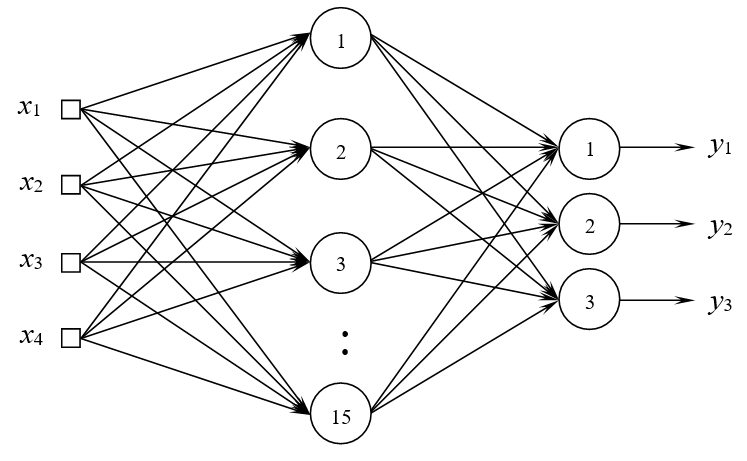


*Fonte*:  SILVA, I.N. – Sistemas Inteligentes – Notas de Aula da disciplina **Redes Neurais Artificiais** – USP São Carlos, 2012

## MLP - inicio

# 2.1 - Configuração dos hiperparâmetros

In [25]:
#CÉLULA MLP-MAIN-01
#IMPLEMENTE O CÓDIGO AQUI - INICIO
#Parâmetros
eta = 0.01
epsilon = 0.000005
nInputs  = 4
nHidden = 15
nOutputs = 3
max_epochs = 10000
dictLayers = {'nLayers' : 2,'vLayers' : np.array([nInputs,nHidden,nOutputs])}

# 2.2 - Carga dos dados e execução do treinamento

In [31]:
#CÉLULA MLP-MAIN-02

#IMPLEMENTE O CÓDIGO AQUI - INICIO
# 1 - FAÇA O CARREGAMENTO DOS DADOS
# 2 - SEPARE EM DOIS VETORES DE DADOS: ENTRADAS E SAIDAS
# 3 - EXECUTE O TREINAMENTO E VERIFIQUE A CONVERGÊNCIA

#Carrega dados - Treino
dfTrainingFile = loadDataFile('Lab02_training.csv')
# dfTrainingFile.drop(columns=('Amostra'), inplace=True)
#dfTrainingFile.head()

nSamples = len(dfTrainingFile['x1'])

vInputs = np.array(dfTrainingFile[['x1','x2','x3','x4']])
vOutputs = np.array(dfTrainingFile[['d1','d2','d3']])
#vInputs.shape
#vOutputs.shape

(W_1,W_2,B_1,B_2,MSE) = mlp_train_online(eta,epsilon,vInputs.T,vOutputs.T,dictLayers,max_epochs)

print(W_1)
print('.............')
print(W_2)

Epoch = 0 - MSE = 0.9912166636394547
Epoch = 1 - MSE = 0.990535212770911
Epoch = 2 - MSE = 0.9897179116646286
Epoch = 3 - MSE = 0.9887182146739926
Epoch = 4 - MSE = 0.9874657246130623
Epoch = 5 - MSE = 0.985848972086258
Epoch = 6 - MSE = 0.9836811532214728
Epoch = 7 - MSE = 0.9806259601650701
Epoch = 8 - MSE = 0.9760190886065665
Epoch = 9 - MSE = 0.9683772744787995
Epoch = 10 - MSE = 0.953814399027328
Epoch = 11 - MSE = 0.920422102808656
Epoch = 12 - MSE = 0.8444413747038421
Epoch = 13 - MSE = 0.7818368009277449
Epoch = 14 - MSE = 0.7677648126390711
Epoch = 15 - MSE = 0.7650570546334585
Epoch = 16 - MSE = 0.7643146858158963
Epoch = 17 - MSE = 0.7639645186384688
Epoch = 18 - MSE = 0.7636931433946774
Epoch = 19 - MSE = 0.7634288579746126
Epoch = 20 - MSE = 0.7631534409487681
Epoch = 21 - MSE = 0.7628611075130814
Epoch = 22 - MSE = 0.7625486696014034
Epoch = 23 - MSE = 0.7622130417521085
Epoch = 24 - MSE = 0.7618505346253043
Epoch = 25 - MSE = 0.7614565455563348
Epoch = 26 - MSE = 0.76102

# 2.3 - Verificação dos resultados do treinamento

Dado que o problema se configura como um típico processo de classificação de padrões, implemente a rotina que faz o pós-processamento das saídas fornecidas pela rede (números reais) para números inteiros. Utilize o critério do arredondamento simétrico, isto é:

$ y_i^{pos} = 1$ se $y_i \geq 0.5 $

$ y_i^{pos} = 0$ se $y_i < 0.5 $

utilizado apenas no pós-processamento do conjunto de teste. 

In [36]:
#Verifica resultados
#IMPLEMENTE O CÓDIGO AQUI - INICIO
# EXECUTE A OPERAÇÃO COM OS DADOS DE TREINAMENTO E VERIFIQUE O RESULTADO 
#PLOTANDO UM GRÁFICO ENTRE OS DADOS DE PREDIÇÃO VERSUS OS DADOS ESPERADOS
y_pred = mlp_operation(vInputs.T, [W_1, W_2], [B_1, B_2])

#Pos-processamento
y_pred[y_pred >= 0.5] = 1.0
y_pred[y_pred < 0.5] = 0.0

y_pred = y_pred.astype(int)
#print(y_pred)

results = vOutputs == y_pred.T
#print(results)

results2 = np.sum(results, axis=1)
results2 = results2 == 3

accuracy = np.sum(results2) / len(results2) * 100
print(accuracy)


95.38461538461539


# 2.4 - Verificação dos resultados de TESTE

In [42]:
#Carrega dados - Teste
#IMPLEMENTE O CÓDIGO AQUI - INICIO
# EXECUTE A OPERAÇÃO COM OS DADOS DE TESTE E VERIFIQUE O RESULTADO 
#PLOTANDO UM GRÁFICO ENTRE OS DADOS DE PREDIÇÃO VERSUS OS DADOS ESPERADOS
dfTestFile = loadDataFile('Lab02_operation.csv')
#dfTestFile.head()

nSamples = len(dfTestFile['x1'])

vInputs = np.array(dfTestFile[['x1','x2','x3','x4']])
vOutputs = np.array(dfTestFile[['d1','d2','d3']])

y_pred = mlp_operation(vInputs.T, [W_1,W_2],[B_1,B_2])

print(y_pred)
print('.............')
print(vOutputs)

#Pos-processamento
y_pred[y_pred >= 0.5] = 1.0
y_pred[y_pred < 0.5] = 0.0

y_pred = y_pred.astype(int)
#print(y_pred)

results = vOutputs == y_pred.T
#print(results)

results2 = np.sum(results, axis=1)
results2 = results2 == 3

accuracy = np.sum(results2) / len(results2) * 100
print(accuracy)


[[4.14081004e-05 9.98835682e-01 3.87927192e-05 2.40453368e-02
  1.38052990e-04 9.14282012e-01 8.72356038e-03 3.59505999e-03
  9.55506100e-01 9.90723344e-01 3.30569145e-03 9.77160604e-01
  2.64454501e-05 3.51143450e-05 2.33498497e-05 9.85501734e-01
  2.88672453e-04 8.54135786e-03]
 [3.71844250e-02 5.49875530e-03 4.05693496e-02 8.95375177e-01
  1.95520138e-01 1.38837901e-01 9.17147211e-01 9.04875897e-01
  8.52902428e-02 2.45612462e-02 8.94373955e-01 5.05328050e-02
  2.95425660e-02 3.54730814e-02 2.59356579e-02 3.80820875e-02
  2.41614518e-01 9.00284672e-01]
 [9.70722562e-01 5.20928872e-06 9.71076839e-01 1.12529496e-02
  8.44808305e-01 1.03236092e-04 2.57399178e-02 5.97757036e-02
  6.01988937e-05 2.12927114e-05 6.69521449e-02 3.86805360e-05
  9.81306567e-01 9.74602618e-01 9.84702484e-01 2.48471457e-05
  7.30508094e-01 2.81269813e-02]]
.............
[[0 0 1]
 [1 0 0]
 [0 0 1]
 [0 1 0]
 [0 0 1]
 [1 0 0]
 [0 1 0]
 [0 1 0]
 [1 0 0]
 [1 0 0]
 [0 1 0]
 [1 0 0]
 [0 0 1]
 [0 0 1]
 [0 0 1]
 [1 0 0

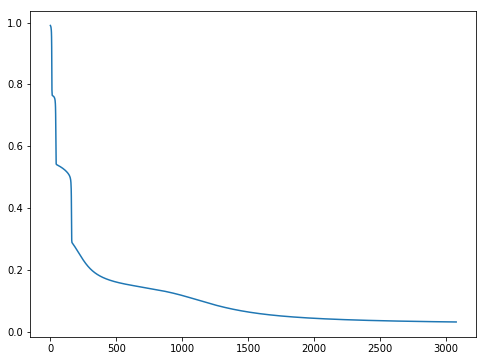

In [45]:
plt.figure(figsize=(8,6))
plt.plot(range(len(MSE) - 1),MSE[1:])
plt.show()